# NeuroCardio — SNN training (device-matched)

Trains the spiking neural network that the NeuroCardio dashboard runs **live on
the laptop**, using MIT-BIH beats that are processed **exactly the way the
Arduino processes the electrode signal**. The model sees the same beat shapes
in training as it will see live.

### What changed from the previous notebook

| | Previous notebook | This notebook | Why |
|---|---|---|---|
| Pre-processing | Butterworth 0.5–40 Hz `filtfilt` at 360 Hz | **Firmware emulation**: 360→200 Hz, 10-bit ADC, 4-tap moving average, IIR high-pass, decimate to the 100 Hz serial stream | Live beats come from the firmware, not from a Butterworth filter |
| Beat window | 0.2 s + 0.4 s at 360 Hz, resampled to 128 | 0.2 s + 0.4 s at **100 Hz = 60 samples**, no resampling | Exactly what the dashboard receives |
| R alignment | Annotation sample | Annotation **snapped to the local maximum** of the filtered stream | That's how the live backend finds R |
| Labels | N/L/R/e/j vs everything else (paced and unclassifiable beats counted abnormal) | **AAMI N vs non-N** (S, V, F). Q-class (`/`, `f`, `Q`) excluded | Standard for MIT-BIH |
| Records | 48, random record split | Paced records 102/104/107/217 excluded. **DS1 → train/val, DS2 → test** (de Chazal inter-patient split) | Standard, comparable with published papers |
| Spike encoding | One channel with values ±1 | **Two spike channels (ON / OFF)**, values 0/1 | Real spikes |
| Training | Last epoch kept | **Best epoch by validation F1**, LR scheduler, early stopping, decision threshold tuned on validation | Validation accuracy swung 0.57 → 0.90 before |
| Efficiency | Input sparsity | Sparsity **+ synaptic operations + energy estimate** vs. the CNN | The Review 2 argument |
| Export | Model not saved | **`neurocardio_snn.pt`** (weights + every pre-processing parameter) and a live-inference check | So the dashboard can load it |

The notebook detects where it runs (**Google Colab**, **Kaggle**, or a local
Jupyter) and adjusts paths, data loading and downloads itself.

### How to run (Google Colab)
1. **Open:** colab.research.google.com → **File → Upload notebook**, and pick this `.ipynb`.
2. **Runtime → Change runtime type → T4 GPU**.
3. **Data:** pick one in the configuration cell (`COLAB_DATA`):
   * `"upload"` (default): when the data cell runs, click **Choose files** and pick `mit-bih-arrhythmia-database-1.0.0.zip`.
   * `"drive"`: put the zip in your Google Drive (top level, or one folder down). The notebook mounts Drive and finds it. This is the fastest option if you re-run often.
   * `"download"`: fetch it from PhysioNet (can be slow).
4. **Runtime → Run all.** Keep the tab open, because Colab stops idle sessions.
5. **Get the model:** the browser downloads **`neurocardio_snn.pt`** and the two result CSVs at the end (allow multiple downloads if asked). They're also in the **Files** panel under `/content`. Put the `.pt` in `NeuroCardio/host/models/`.

### How to run (Kaggle)
1. **Import:** kaggle.com → **Create → New Notebook**, then **File → Import Notebook** and pick this `.ipynb`.
2. **Settings** (right-hand panel):
   * **Accelerator → GPU T4 x2**. T4 is the safe choice: the P100 may not be supported by the PyTorch version Kaggle ships, and the notebook falls back to CPU if the GPU fails.
   * **Internet → On**. This is needed for `pip install wfdb snntorch`, and Kaggle only allows it on phone-verified accounts.
3. **Data:** **Add Input → Upload → New Dataset**, then upload `mit-bih-arrhythmia-database-1.0.0.zip`. Kaggle extracts it under `/kaggle/input/...`, and the notebook finds the records anywhere in there. If no MIT-BIH input is attached, it downloads the data from PhysioNet instead (slower).
4. **Run:** **Run All** to watch it, or **Save Version → Save & Run All (Commit)** to let it run in the background (the session can close).
5. **Get the model:** everything is written to `/kaggle/working`. Download **`neurocardio_snn.pt`** from the **Output** panel (or the version's *Output* tab after a commit, or the links printed at the end). Put it in `NeuroCardio/host/models/`.

Set `QUICK_TEST = True` for a ~2-minute dry run on a few records. The numbers will be meaningless; use it only to check that everything runs.

In [1]:
!pip install -q wfdb snntorch

In [2]:
import os, glob, json, time, random, zipfile, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

from scipy.signal import resample_poly, lfilter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import snntorch as snn
from snntorch import surrogate

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from IPython.display import FileLink, display

# where are we running?
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files, IN_COLAB = None, False
IN_KAGGLE = os.path.isdir("/kaggle/working")
PLATFORM = "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local"

# some GPUs (e.g. Kaggle's P100) aren't supported by recent PyTorch: test it, fall back to CPU
if DEVICE.type == "cuda":
    try:
        (torch.ones(8, device=DEVICE) * 2).sum().item()
        print("GPU:", torch.cuda.get_device_name(0))
    except Exception as e:
        print(f"GPU unusable ({str(e).splitlines()[0]}) -> using CPU. Choose a T4 GPU runtime.")
        DEVICE = torch.device("cpu")
elif IN_COLAB or IN_KAGGLE:
    print("No GPU - training will be slow. Colab: Runtime -> Change runtime type -> T4 GPU. "
          "Kaggle: Settings -> Accelerator -> GPU T4 x2.")

print(f"Platform: {PLATFORM} | PyTorch {torch.__version__} | snnTorch {snn.__version__} | device: {DEVICE}")

GPU: Tesla T4
Platform: Colab | PyTorch 2.11.0+cu130 | snnTorch 1.0.0 | device: cuda


## 1. Configuration

Every number the live dashboard needs to reproduce the pre-processing is
defined here and saved into the model file at the end.

In [3]:
QUICK_TEST  = False          # True = few records, few epochs (pipeline check only)

COLAB_DATA  = "upload"       # Colab only: "upload" the zip, "drive" (zip in Google Drive), or "download"
DATA_DIR    = None           # or a folder containing 100.hea, to skip the search

# Colab works in /content; Kaggle reads /kaggle/input (read-only) and writes /kaggle/working
WORK_DIR = "/content" if IN_COLAB else "/kaggle/working" if IN_KAGGLE else os.getcwd()
os.chdir(WORK_DIR)

# ---- firmware constants (firmware/NeuroCardio_Review1.ino) ----
FS_DEVICE   = 200            # ADC sampling rate
FS_STREAM   = 100            # 'D,' serial stream (every 2nd filtered sample)
ADC_MV_PER_COUNT = 5000 / 1024 / 1000   # 5 V, 10-bit ADC, module gain 1000
ADC_MID     = 512            # module output sits around mid-rail
BASE_SHIFT  = 8              # IIR high-pass: time constant 256 samples = 1.28 s
Q4_TO_MV    = 0.00122075     # stream units -> mV (Q4_TO_MV_BASE in the sketch)

# ---- beat window (in 100 Hz stream samples) ----
PRE_SEC, POST_SEC = 0.20, 0.40
PRE   = int(round(PRE_SEC * FS_STREAM))      # 20 samples before R
POST  = int(round(POST_SEC * FS_STREAM))     # 40 samples from R onwards
N_STEPS = PRE + POST                         # 60 time steps per beat
ALIGN_SEARCH = 8             # snap annotation to the max within +/- 80 ms
WARMUP_SEC = 3               # drop beats while the high-pass settles

# ---- spike encoding ----
LC_THRESHOLD = 0.30          # level-crossing step, in units of beat std

# ---- network / training ----
HIDDEN   = 64
BETA     = 0.90
BATCH    = 256
EPOCHS   = 30
LR       = 1e-3
PATIENCE = 6                 # early stopping on validation F1
RUN_BASELINES = True         # also train RF + 1D CNN on the same beats

if QUICK_TEST:
    EPOCHS, PATIENCE = 3, 2

print(f"Window: {PRE} + {POST} = {N_STEPS} samples at {FS_STREAM} Hz")

Window: 20 + 40 = 60 samples at 100 Hz


## 2. Get MIT-BIH

In [4]:
def find_mitdb(*roots):
    # folder that holds 100.hea / 100.dat / 100.atr, searched recursively
    for root in roots:
        if root and os.path.isdir(root):
            for hea in glob.glob(os.path.join(root, "**", "100.hea"), recursive=True):
                d = os.path.dirname(hea)
                if os.path.exists(os.path.join(d, "100.dat")) and os.path.exists(os.path.join(d, "100.atr")):
                    return d
    return None


def mit_zips(pattern, recursive=False):
    return [z for z in glob.glob(pattern, recursive=recursive) if "mit" in os.path.basename(z).lower()]


local_copy = os.path.join(WORK_DIR, "mitdb")
DATA_DIR = find_mitdb(DATA_DIR, local_copy, "/kaggle/input" if IN_KAGGLE else None)

if DATA_DIR is None:
    zips = []
    if IN_KAGGLE:
        # a zip attached as a Kaggle input that was not auto-extracted
        zips = mit_zips("/kaggle/input/**/*.zip", recursive=True)
    elif IN_COLAB:
        zips = mit_zips("/content/*.zip")                       # uploaded in an earlier run
        if not zips and COLAB_DATA == "drive":
            from google.colab import drive
            drive.mount("/content/drive")
            zips = mit_zips("/content/drive/MyDrive/*.zip") + mit_zips("/content/drive/MyDrive/*/*.zip")
            if not zips:
                print("No mit-bih*.zip at the top of My Drive (or one folder down).")
        if not zips and COLAB_DATA == "upload":
            print("Choose mit-bih-arrhythmia-database-1.0.0.zip in the button below ...")
            uploaded = colab_files.upload()                       # saved into /content
            zips = [os.path.join(WORK_DIR, n) for n in uploaded if n.lower().endswith(".zip")]
    else:
        zips = mit_zips(os.path.join(WORK_DIR, "*.zip"))        # local Jupyter: zip next to the notebook

    if zips:
        print("Extracting", zips[0])
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(local_copy)
    else:
        print("Downloading MIT-BIH from PhysioNet (needs internet; can take a while) ...")
        t0 = time.time()
        wfdb.dl_database("mitdb", local_copy)
        print(f"Downloaded in {time.time() - t0:.0f} s")
    DATA_DIR = find_mitdb(local_copy)

if DATA_DIR is None:
    raise FileNotFoundError(
        "MIT-BIH not found. Colab: set COLAB_DATA to 'upload', 'drive' or 'download'. "
        "Kaggle: attach the zip with Add Input, or turn Internet on.")


def record_path(rec):
    path = os.path.join(DATA_DIR, str(rec))
    if not os.path.exists(path + ".hea"):
        raise FileNotFoundError(f"record {rec} not found in {DATA_DIR}")
    return path

print("MIT-BIH records in:", DATA_DIR)

Choose mit-bih-arrhythmia-database-1.0.0.zip in the button below ...


Saving mit-bih-arrhythmia-database-1.0.0.zip to mit-bih-arrhythmia-database-1.0.0.zip
Extracting /content/mit-bih-arrhythmia-database-1.0.0.zip
MIT-BIH records in: /content/mitdb/mit-bih-arrhythmia-database-1.0.0


## 3. Records, labels and the inter-patient split

* **AAMI classes**: **N** (N, L, R, e, j) vs **non-N** = S (A, a, J, S) + V (V, E) + F (F).
  Q-class beats (`/` paced, `f` fusion of paced, `Q` unclassifiable) are excluded.
* **Paced records** 102, 104, 107, 217 are excluded (AAMI recommendation).
* **DS1 / DS2** (de Chazal et al., 2004): no patient appears in both training and
  test, the standard inter-patient protocol. Validation records are held out of DS1.

> Inter-patient results are **lower** than random-split results. That's expected
> and it's the honest number: the dashboard will see a patient it never trained on.

In [5]:
N_SYMBOLS   = {"N", "L", "R", "e", "j"}
ABN_SYMBOLS = {"A", "a", "J", "S", "V", "E", "F"}
CLASSES     = ["Normal", "Abnormal"]          # AAMI N vs non-N

DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124,
       201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212,
       213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
VAL_RECORDS   = [106, 119, 209]               # held out of DS1 (they contain V and S beats)
TRAIN_RECORDS = [r for r in DS1 if r not in VAL_RECORDS]
TEST_RECORDS  = DS2

if QUICK_TEST:
    TRAIN_RECORDS, VAL_RECORDS, TEST_RECORDS = [101, 208, 118], [119], [100, 233]

print("train:", TRAIN_RECORDS)
print("val:  ", VAL_RECORDS)
print("test: ", TEST_RECORDS)

train: [101, 108, 109, 112, 114, 115, 116, 118, 122, 124, 201, 203, 205, 207, 208, 215, 220, 223, 230]
val:   [106, 119, 209]
test:  [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]


## 4. Emulate the NeuroCardio firmware

This reproduces `processSample()` from the sketch:

```c
maSum += raw - maRing[maIdx];                 // 4-tap moving average (nulls 50/100 Hz)
int32_t base = baseAcc >> BASE_SHIFT;         // slow baseline
baseAcc += maSum - base;
int16_t fq = maSum - base;                    // high-passed sample, Q4 units
if (decimate = !decimate) Serial.println(fq); // every 2nd sample -> 100 Hz stream
```

MIT-BIH (360 Hz, mV) is first converted to what the Arduino's ADC would read
(200 Hz, 10-bit counts). The high-pass is computed with `lfilter`, the
floating-point form of the same recursion. It matches the integer version
to within one LSB.

In [6]:
def mv_to_adc(sig_mv, fs_in):
    # resample to the device rate and quantise like the 10-bit ADC
    x = resample_poly(sig_mv, FS_DEVICE, fs_in)
    counts = np.round(x / ADC_MV_PER_COUNT) + ADC_MID
    return np.clip(counts, 0, 1023)


def firmware_filter(adc):
    # 4-tap moving average + IIR high-pass, at 200 Hz, output in Q4 units
    ma = np.convolve(adc, np.ones(4), mode="full")[: len(adc)]       # maRing starts at 0
    k = 1.0 / (1 << BASE_SHIFT)
    # base[n] = base[n-1] + k*(ma[n-1] - base[n-1]),  base[0] = ma[0]
    base = lfilter([0.0, k], [1.0, -(1.0 - k)], ma, zi=[ma[0]])[0]
    return ma - base


def device_stream(sig_mv, fs_in):
    # what the laptop receives on the 'D,' lines, in mV at 100 Hz
    fq = firmware_filter(mv_to_adc(sig_mv, fs_in))
    return (fq[::2] * Q4_TO_MV).astype(np.float32)


# sanity check against the exact integer implementation on 20 s of record 100
rec = wfdb.rdrecord(record_path("100"))
adc = mv_to_adc(rec.p_signal[: 20 * rec.fs, 0], rec.fs).astype(np.int64)
ma_sum, ring, idx, base_acc, ints = 0, [0, 0, 0, 0], 0, None, []
for raw in adc:
    ma_sum += raw - ring[idx]; ring[idx] = raw; idx = (idx + 1) & 3
    if base_acc is None: base_acc = ma_sum << BASE_SHIFT
    base = base_acc >> BASE_SHIFT
    base_acc += ma_sum - base
    ints.append(ma_sum - base)
err = np.abs(np.array(ints) - firmware_filter(adc.astype(float)))
print(f"float vs integer firmware filter: max diff {err.max():.2f} Q4 units "
      f"(signal range {np.ptp(ints)} Q4 units)")

float vs integer firmware filter: max diff 0.97 Q4 units (signal range 2003 Q4 units)


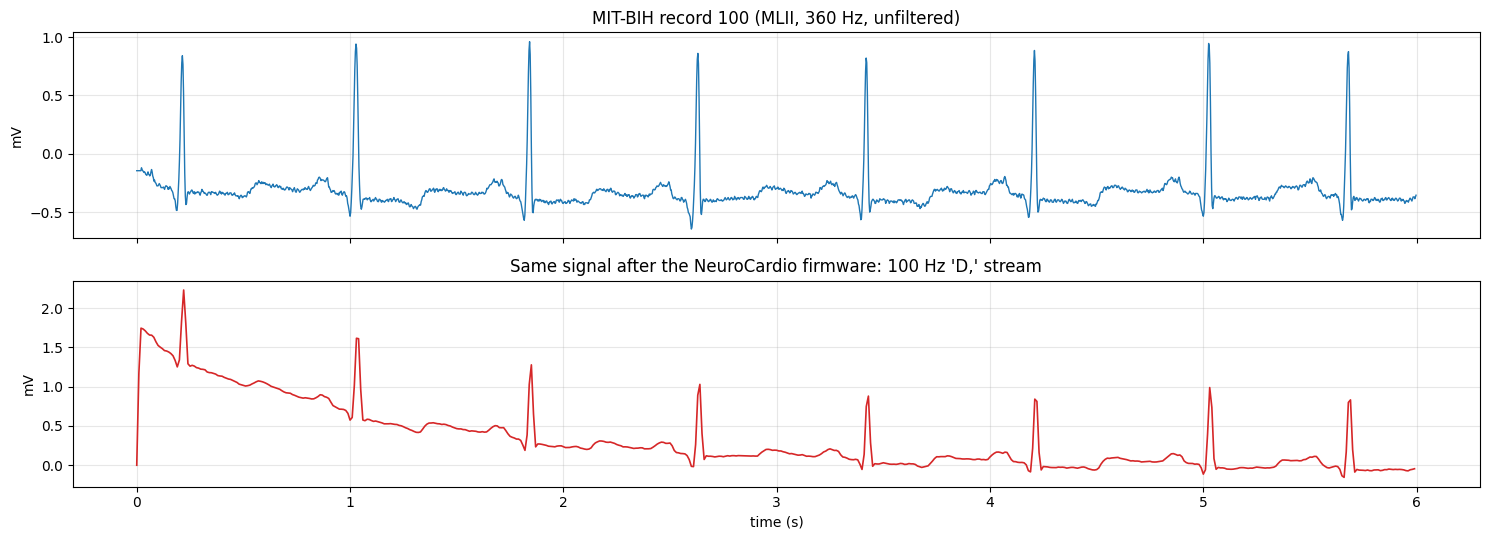

In [7]:
# what changes between the raw MIT-BIH trace and what the dashboard will see
fs = rec.fs
raw = rec.p_signal[: 6 * fs, 0]
dev = device_stream(rec.p_signal[:, 0], fs)[: 6 * FS_STREAM]

fig, ax = plt.subplots(2, 1, figsize=(15, 5.5), sharex=True)
ax[0].plot(np.arange(len(raw)) / fs, raw, lw=1)
ax[0].set_title("MIT-BIH record 100 (MLII, 360 Hz, unfiltered)"); ax[0].set_ylabel("mV")
ax[1].plot(np.arange(len(dev)) / FS_STREAM, dev, lw=1.2, color="tab:red")
ax[1].set_title("Same signal after the NeuroCardio firmware: 100 Hz 'D,' stream"); ax[1].set_ylabel("mV")
ax[1].set_xlabel("time (s)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Cut beats the way the live backend will

The backend keeps the 100 Hz stream in a buffer. When a beat is reported, it
takes the **maximum of the recent samples** as R, waits 0.4 s, and cuts
`[R-20, R+40)`. The next cell does the same, snapping each annotation to the
local maximum. `beat_from_stream()` is the function the dashboard must reproduce.

In [8]:
def normalize_beat(beat):
    beat = np.asarray(beat, dtype=np.float32)
    s = beat.std()
    return beat - np.median(beat) if s < 1e-8 else (beat - np.median(beat)) / s


def snap_to_peak(stream, idx, search=ALIGN_SEARCH):
    lo, hi = max(0, idx - search), min(len(stream), idx + search + 1)
    return lo + int(np.argmax(stream[lo:hi]))


def beat_from_stream(stream, r_idx):
    # the window the live system classifies: 60 samples, normalised
    s, e = r_idx - PRE, r_idx + POST
    if s < 0 or e > len(stream):
        return None
    return normalize_beat(stream[s:e])


def process_record(rec_id):
    path = record_path(rec_id)
    rec = wfdb.rdrecord(path)
    ann = wfdb.rdann(path, "atr")
    lead = rec.sig_name.index("MLII") if "MLII" in rec.sig_name else 0
    stream = device_stream(rec.p_signal[:, lead], rec.fs)

    X, y = [], []
    for samp, sym in zip(ann.sample, ann.symbol):
        if sym in N_SYMBOLS:
            label = 0
        elif sym in ABN_SYMBOLS:
            label = 1
        else:
            continue
        idx = int(round(samp * FS_STREAM / rec.fs))
        if idx < WARMUP_SEC * FS_STREAM:
            continue
        beat = beat_from_stream(stream, snap_to_peak(stream, idx))
        if beat is not None:
            X.append(beat); y.append(label)
    return np.array(X, np.float32), np.array(y, np.int64)


def build(records):
    Xs, ys, ids = [], [], []
    for r in records:
        X, y = process_record(r)
        Xs.append(X); ys.append(y); ids += [r] * len(y)
        print(f"  {r}: {len(y):5d} beats, {int(y.sum()):4d} non-N")
    return np.concatenate(Xs), np.concatenate(ys), np.array(ids)


t0 = time.time()
print("TRAIN"); X_train, y_train, id_train = build(TRAIN_RECORDS)
print("VAL");   X_val,   y_val,   id_val   = build(VAL_RECORDS)
print("TEST");  X_test,  y_test,  id_test  = build(TEST_RECORDS)
print(f"\nbuilt in {time.time() - t0:.0f} s")

summary = pd.DataFrame({
    "beats": [len(y_train), len(y_val), len(y_test)],
    "non-N": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["train", "val", "test"])
summary["non-N %"] = (100 * summary["non-N"] / summary["beats"]).round(1)
summary

TRAIN
  101:  1859 beats,    3 non-N
  108:  1760 beats,   23 non-N
  109:  2526 beats,   40 non-N
  112:  2534 beats,    2 non-N
  114:  1877 beats,   59 non-N
  115:  1949 beats,    0 non-N
  116:  2408 beats,  110 non-N
  118:  2274 beats,  112 non-N
  122:  2470 beats,    0 non-N
  124:  1616 beats,   83 non-N
  201:  1959 beats,  328 non-N
  203:  2971 beats,  447 non-N
  205:  2651 beats,   85 non-N
  207:  1856 beats,  315 non-N
  208:  2947 beats, 1363 non-N
  215:  3357 beats,  168 non-N
  220:  2043 beats,   94 non-N
  223:  2601 beats,  560 non-N
  230:  2252 beats,    1 non-N
VAL
  106:  2025 beats,  520 non-N
  119:  1984 beats,  443 non-N
  209:  3000 beats,  384 non-N
TEST
  100:  2268 beats,   34 non-N
  103:  2080 beats,    2 non-N
  105:  2563 beats,   41 non-N
  111:  2121 beats,    1 non-N
  113:  1791 beats,    6 non-N
  117:  1531 beats,    1 non-N
  121:  1859 beats,    2 non-N
  123:  1515 beats,    3 non-N
  200:  2596 beats,  856 non-N
  202:  2133 beats,   75

,beats,non-N,non-N %
train,43910,3793,8.6
val,7009,1347,19.2
test,49610,5438,11.0


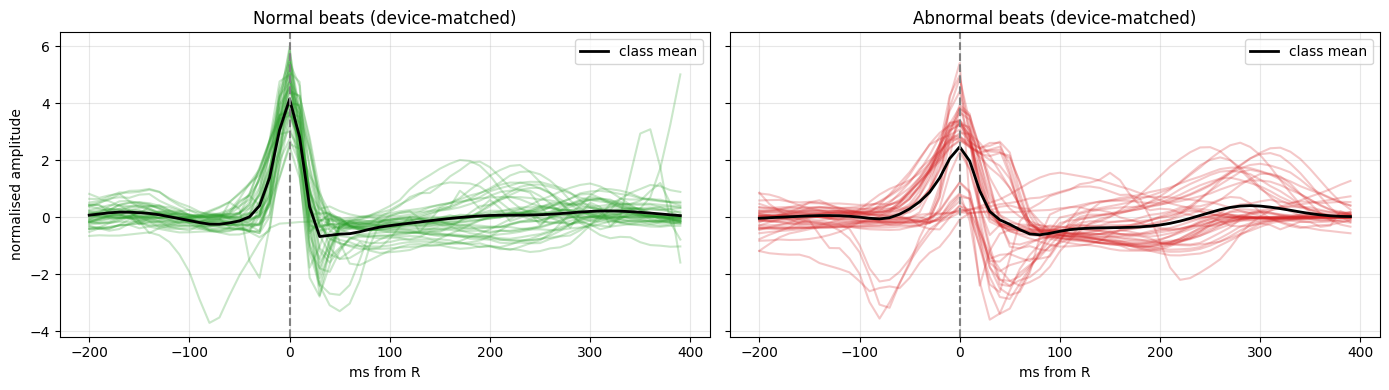

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
t = (np.arange(N_STEPS) - PRE) / FS_STREAM * 1000
for lab, a in zip([0, 1], ax):
    idx = np.random.choice(np.where(y_train == lab)[0], 40, replace=False)
    for i in idx:
        a.plot(t, X_train[i], alpha=.25, color="tab:green" if lab == 0 else "tab:red")
    a.plot(t, X_train[y_train == lab].mean(0), color="k", lw=2, label="class mean")
    a.axvline(0, ls="--", c="grey"); a.set_title(f"{CLASSES[lab]} beats (device-matched)")
    a.set_xlabel("ms from R"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("normalised amplitude")
plt.tight_layout(); plt.show()

## 6. Level-crossing spike encoding (ON / OFF channels)

A tracking reference follows the beat. When the signal rises one threshold
above it, the **ON** neuron fires. When it falls one threshold below, the
**OFF** neuron fires. The output is two binary spike trains of 60 steps, so the
network only processes **events**.

encoded in 5 s | shape (43910, 60, 2) | event rate 0.144 per channel-step -> input sparsity 85.6%


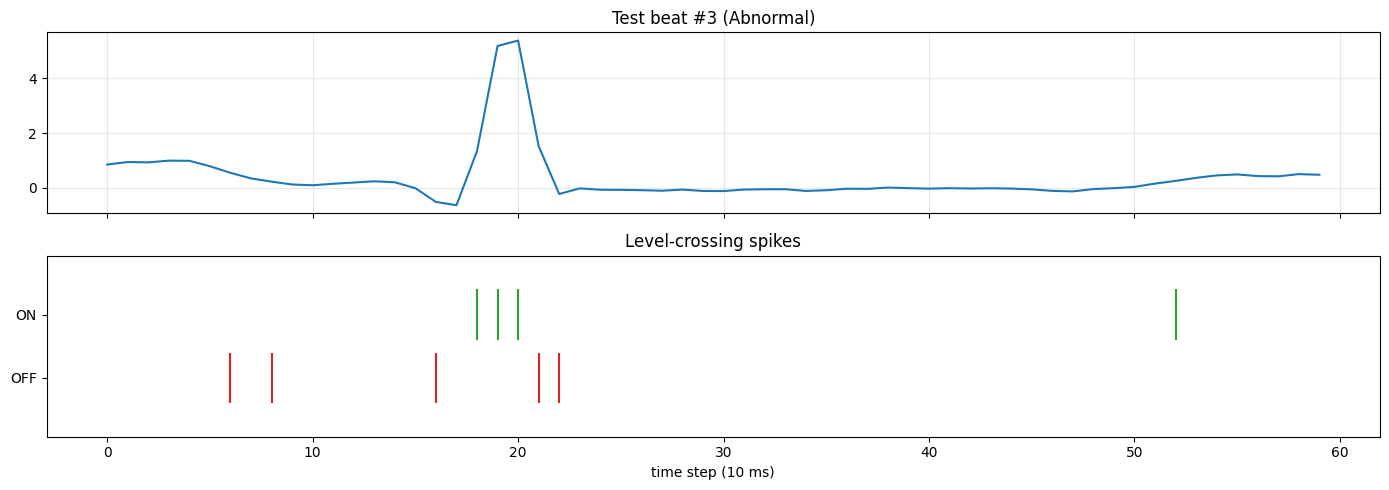

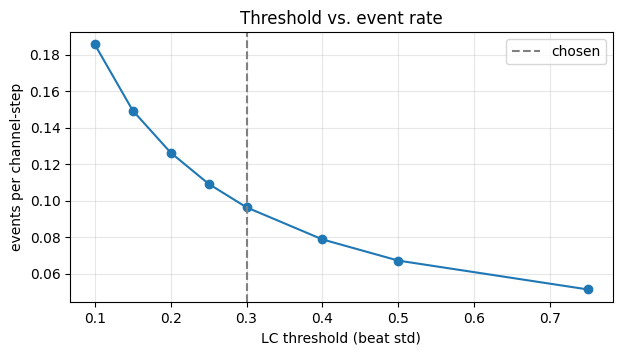

In [10]:
def level_crossing_encode(beat, threshold=LC_THRESHOLD):
    # -> spikes [N_STEPS, 2] (ON, OFF), values 0/1
    spikes = np.zeros((len(beat), 2), np.float32)
    ref = beat[0]
    for t in range(1, len(beat)):
        d = beat[t] - ref
        if d >= threshold:
            spikes[t, 0] = 1
            ref += threshold * np.floor(d / threshold)
        elif d <= -threshold:
            spikes[t, 1] = 1
            ref -= threshold * np.floor(-d / threshold)
    return spikes


def encode_all(X):
    return np.stack([level_crossing_encode(b) for b in X])


t0 = time.time()
S_train, S_val, S_test = encode_all(X_train), encode_all(X_val), encode_all(X_test)
rate = S_test.mean()
print(f"encoded in {time.time() - t0:.0f} s | shape {S_train.shape} | "
      f"event rate {rate:.3f} per channel-step -> input sparsity {1 - rate:.1%}")

# one beat and its spikes
i = int(np.where(y_test == 1)[0][0])
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax[0].plot(X_test[i]); ax[0].set_title(f"Test beat #{i} ({CLASSES[y_test[i]]})"); ax[0].grid(alpha=.3)
on, off = np.where(S_test[i, :, 0])[0], np.where(S_test[i, :, 1])[0]
ax[1].eventplot([on, off], colors=["tab:green", "tab:red"], lineoffsets=[1, 0], linelengths=.8)
ax[1].set_yticks([0, 1], ["OFF", "ON"]); ax[1].set_xlabel("time step (10 ms)")
ax[1].set_title("Level-crossing spikes"); plt.tight_layout(); plt.show()

ths = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.75]
sub = X_test[:2000]
rates = [np.mean([level_crossing_encode(b, th).mean() for b in sub]) for th in ths]
plt.figure(figsize=(7, 3.5)); plt.plot(ths, rates, "o-")
plt.axvline(LC_THRESHOLD, ls="--", c="grey", label="chosen")
plt.xlabel("LC threshold (beat std)"); plt.ylabel("events per channel-step")
plt.title("Threshold vs. event rate"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 7. The spiking network

`2 inputs (ON/OFF) → 64 LIF → 64 LIF → 2 outputs`, unrolled over the 60 time
steps. The class score is the output current summed over time. Hidden spike
counts are returned so the efficiency section can count synaptic operations.

In [11]:
class ECG_SNN(nn.Module):
    def __init__(self, n_in=2, hidden=HIDDEN, beta=BETA):
        super().__init__()
        grad = surrogate.fast_sigmoid(slope=25)
        self.fc1, self.lif1 = nn.Linear(n_in, hidden), snn.Leaky(beta=beta, spike_grad=grad)
        self.fc2, self.lif2 = nn.Linear(hidden, hidden), snn.Leaky(beta=beta, spike_grad=grad)
        self.fc3 = nn.Linear(hidden, 2)

    def forward(self, x):
        # x: [batch, T, 2] -> logits [batch, 2], spikes per layer [batch]
        mem1, mem2 = self.lif1.init_leaky(), self.lif2.init_leaky()
        logits = 0
        n1 = n2 = 0
        for t in range(x.size(1)):
            spk1, mem1 = self.lif1(self.fc1(x[:, t]), mem1)
            spk2, mem2 = self.lif2(self.fc2(spk1), mem2)
            logits = logits + self.fc3(spk2)
            n1 = n1 + spk1.sum(1)
            n2 = n2 + spk2.sum(1)
        return logits, n1, n2


def loader(S, y, shuffle):
    return DataLoader(TensorDataset(torch.tensor(S), torch.tensor(y)), batch_size=BATCH, shuffle=shuffle)

train_dl, val_dl, test_dl = loader(S_train, y_train, True), loader(S_val, y_val, False), loader(S_test, y_test, False)

snn_model = ECG_SNN().to(DEVICE)
print(snn_model)
print("parameters:", sum(p.numel() for p in snn_model.parameters()))

ECG_SNN(
  (fc1): Linear(in_features=2, out_features=64, bias=True)
  (lif1): Leaky()
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (lif2): Leaky()
  (fc3): Linear(in_features=64, out_features=2, bias=True)
)
parameters: 4482


In [12]:
def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Sensitivity": recall_score(y_true, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else 0.0,
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob) if len(set(y_true)) > 1 else float("nan"),
    }


@torch.no_grad()
def predict(model, dl):
    model.eval()
    probs, n1, n2 = [], [], []
    for xb, _ in dl:
        logits, s1, s2 = model(xb.to(DEVICE))
        probs.append(torch.softmax(logits, 1)[:, 1].cpu()); n1.append(s1.cpu()); n2.append(s2.cpu())
    return torch.cat(probs).numpy(), torch.cat(n1).numpy(), torch.cat(n2).numpy()


w = torch.tensor(len(y_train) / (2 * np.bincount(y_train, minlength=2)), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=w)
optimizer = torch.optim.Adam(snn_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
print("class weights:", w.cpu().numpy().round(3))

class weights: [0.547 5.788]


epoch  1 | loss 0.5546 | val F1 0.271 sens 0.362 spec 0.690 | lr 1.0e-03  <- best
epoch  2 | loss 0.4624 | val F1 0.359 sens 0.644 spec 0.537 | lr 1.0e-03  <- best
epoch  3 | loss 0.4291 | val F1 0.387 sens 0.664 spec 0.580 | lr 1.0e-03  <- best
epoch  4 | loss 0.4178 | val F1 0.473 sens 0.555 spec 0.812 | lr 1.0e-03  <- best
epoch  5 | loss 0.4232 | val F1 0.453 sens 0.359 spec 0.946 | lr 1.0e-03
epoch  6 | loss 0.4027 | val F1 0.485 sens 0.610 spec 0.784 | lr 1.0e-03  <- best
epoch  7 | loss 0.3860 | val F1 0.474 sens 0.700 spec 0.701 | lr 1.0e-03
epoch  8 | loss 0.3744 | val F1 0.364 sens 0.780 spec 0.403 | lr 1.0e-03
epoch  9 | loss 0.3758 | val F1 0.376 sens 0.780 spec 0.437 | lr 5.0e-04
epoch 10 | loss 0.3590 | val F1 0.455 sens 0.715 spec 0.660 | lr 5.0e-04
epoch 11 | loss 0.3562 | val F1 0.508 sens 0.690 spec 0.756 | lr 5.0e-04  <- best
epoch 12 | loss 0.3557 | val F1 0.495 sens 0.674 spec 0.750 | lr 5.0e-04
epoch 13 | loss 0.3516 | val F1 0.498 sens 0.694 spec 0.740 | lr 5.0e-

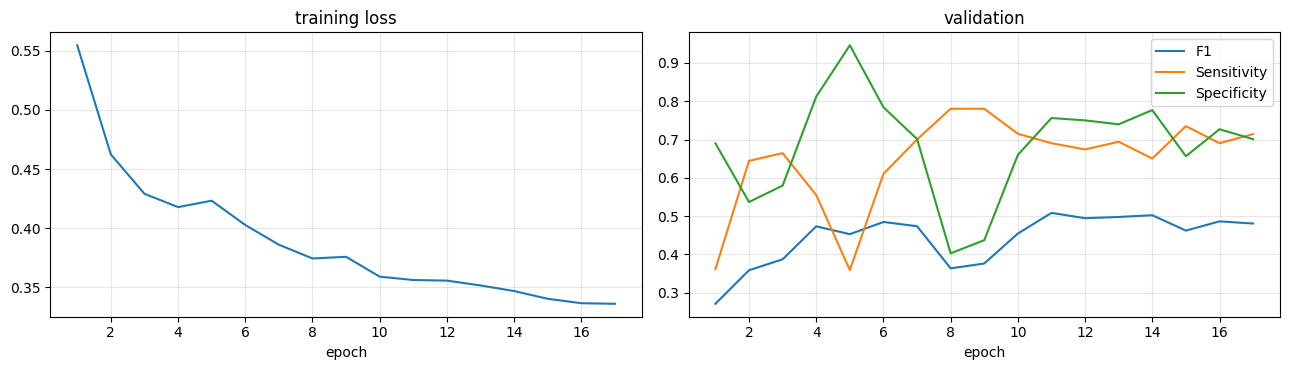

In [13]:
history, best_f1, best_state, bad = [], -1.0, None, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    snn_model.train()
    tot, n = 0.0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits, _, _ = snn_model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        tot += loss.item() * len(yb); n += len(yb)

    p_val, _, _ = predict(snn_model, val_dl)
    m = metrics(y_val, p_val)
    scheduler.step(m["F1"])
    history.append({"epoch": epoch, "train_loss": tot / n, **{f"val_{k}": v for k, v in m.items()}})
    flag = ""
    if m["F1"] > best_f1:
        best_f1, bad, flag = m["F1"], 0, "  <- best"
        best_state = {k: v.detach().cpu().clone() for k, v in snn_model.state_dict().items()}
    else:
        bad += 1
    print(f"epoch {epoch:2d} | loss {tot / n:.4f} | val F1 {m['F1']:.3f} sens {m['Sensitivity']:.3f} "
          f"spec {m['Specificity']:.3f} | lr {optimizer.param_groups[0]['lr']:.1e}{flag}")
    if bad >= PATIENCE:
        print("early stop"); break

snn_train_time = time.time() - t0
snn_model.load_state_dict(best_state)
print(f"\ntrained in {snn_train_time / 60:.1f} min, best val F1 {best_f1:.3f}")

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title("training loss")
for k in ["val_F1", "val_Sensitivity", "val_Specificity"]:
    ax[1].plot(h.epoch, h[k], label=k[4:])
ax[1].set_title("validation"); ax[1].legend()
for a in ax: a.grid(alpha=.3); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 8. Decision threshold and test results

Instead of the default 0.5, the abnormal-probability threshold is chosen on
**validation** (best F1) and then applied unchanged to the test set. The
dashboard uses the same threshold, saved in the model file.

In [14]:
p_val, _, _ = predict(snn_model, val_dl)
grid = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_val, (p_val >= g).astype(int), zero_division=0) for g in grid]
DECISION_THRESHOLD = float(grid[int(np.argmax(f1s))])
print(f"decision threshold (best val F1): {DECISION_THRESHOLD:.2f}")

t0 = time.time()
snn_prob, snn_n1, snn_n2 = predict(snn_model, test_dl)
snn_infer_ms = (time.time() - t0) / len(y_test) * 1000

snn_metrics = metrics(y_test, snn_prob, DECISION_THRESHOLD)
pd.DataFrame({"SNN @0.5": metrics(y_test, snn_prob, 0.5),
              f"SNN @{DECISION_THRESHOLD:.2f}": snn_metrics}).T.round(4)

decision threshold (best val F1): 0.63


,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC
SNN @0.5,0.6841,0.2096,0.6789,0.6848,0.3203,0.7423
SNN @0.63,0.7495,0.2309,0.5513,0.7739,0.3255,0.7423


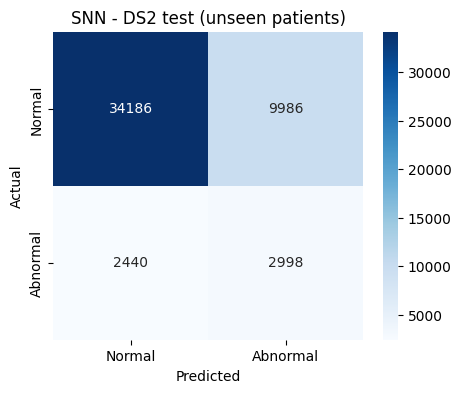

,beats,non-N,sensitivity,false-alarm rate
record,,,,
100,2268.0,34.0,0.000,0.002
103,2080.0,2.0,0.000,0.004
105,2563.0,41.0,0.146,0.096
111,2121.0,1.0,1.000,0.555
113,1791.0,6.0,1.000,0.836
117,1531.0,1.0,1.000,0.731
121,1859.0,2.0,0.500,0.142
123,1515.0,3.0,1.000,0.006
200,2596.0,856.0,0.558,0.006


In [15]:
cm = confusion_matrix(y_test, (snn_prob >= DECISION_THRESHOLD).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("SNN - DS2 test (unseen patients)")
plt.show()

per_rec = pd.DataFrame({"record": id_test, "y": y_test,
                        "pred": (snn_prob >= DECISION_THRESHOLD).astype(int)})
per_rec = per_rec.groupby("record").apply(lambda d: pd.Series({
    "beats": len(d), "non-N": int(d.y.sum()),
    "sensitivity": ((d.pred == 1) & (d.y == 1)).sum() / max(1, d.y.sum()),
    "false-alarm rate": ((d.pred == 1) & (d.y == 0)).sum() / max(1, (d.y == 0).sum()),
})).round(3)
per_rec

## 9. Efficiency: why an SNN

On neuromorphic hardware an SNN only does work when a spike arrives. Each
input or hidden spike costs one **accumulate** (AC) per outgoing synapse, while
a conventional network does a **multiply-accumulate** (MAC) for every weight.
The energy figures use the commonly quoted 45 nm CMOS estimates (Horowitz,
ISSCC 2014: 4.6 pJ per 32-bit MAC, 0.9 pJ per AC). Treat them as an
**estimate**, not a measurement. Running the SNN on a laptop CPU/GPU does not save
energy. The saving needs event-driven hardware.

In [16]:
E_MAC, E_AC = 4.6e-12, 0.9e-12
in_events = S_test.sum(axis=(1, 2))                    # input spikes per beat

# SNN synaptic operations per beat (event-driven)
snn_sops = in_events * HIDDEN + snn_n1 * HIDDEN + snn_n2 * 2
# the same network run as a dense ANN for all 60 steps
dense_macs = N_STEPS * (2 * HIDDEN + HIDDEN * HIDDEN + HIDDEN * 2)

eff = pd.DataFrame({
    "per beat": {
        "input events": in_events.mean(),
        "hidden-1 spikes": snn_n1.mean(),
        "hidden-2 spikes": snn_n2.mean(),
        "SNN synaptic ops (AC)": snn_sops.mean(),
        "same net, dense (MAC)": dense_macs,
        "SNN energy (nJ, est.)": snn_sops.mean() * E_AC * 1e9,
        "dense energy (nJ, est.)": dense_macs * E_MAC * 1e9,
    }
}).round(2)
print(f"input sparsity: {1 - S_test.mean():.1%}   "
      f"hidden-1 firing rate: {snn_n1.mean() / (HIDDEN * N_STEPS):.1%}   "
      f"hidden-2 firing rate: {snn_n2.mean() / (HIDDEN * N_STEPS):.1%}")
print(f"SNN inference on {DEVICE}: {snn_infer_ms:.3f} ms per beat (batched)")
eff

input sparsity: 85.6%   hidden-1 firing rate: 12.5%   hidden-2 firing rate: 2.9%
SNN inference on cuda: 0.236 ms per beat (batched)


,per beat
input events,17.33
hidden-1 spikes,480.44
hidden-2 spikes,113.02
SNN synaptic ops (AC),32082.86
"same net, dense (MAC)",261120.00
"SNN energy (nJ, est.)",28.87
"dense energy (nJ, est.)",1201.15


## 10. Baselines on the same beats

Random Forest (the notebook's 8 morphology features) and a 1D CNN, trained on
the **same device-matched beats and split**, so the comparison is fair. Set
`RUN_BASELINES = False` to skip.

In [17]:
def rf_features(b):
    r = int(np.argmax(b))
    return [b[: int(.3 * len(b))].max(), b.min(), b.max(), b[int(.65 * len(b)):].max(),
            b[:r].mean() if r > 0 else 0, b[r:].mean(), np.sum(b ** 2), np.abs(np.diff(b)).max()]

results = {"SNN": snn_metrics}
roc = {"SNN": snn_prob}

if RUN_BASELINES:
    F_train, F_val, F_test = (np.array([rf_features(b) for b in X]) for X in (X_train, X_val, X_test))
    rf = RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=2,
                                class_weight="balanced", n_jobs=-1, random_state=SEED).fit(F_train, y_train)
    rf_val = rf.predict_proba(F_val)[:, 1]
    rf_thr = grid[int(np.argmax([f1_score(y_val, (rf_val >= g).astype(int), zero_division=0) for g in grid]))]
    roc["Random Forest"] = rf.predict_proba(F_test)[:, 1]
    results["Random Forest"] = metrics(y_test, roc["Random Forest"], rf_thr)

    class ECG_CNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.f = nn.Sequential(
                nn.Conv1d(1, 16, 7, padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
                nn.Conv1d(16, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
                nn.Conv1d(32, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
            self.c = nn.Linear(64, 2)
        def forward(self, x):
            return self.c(self.f(x).squeeze(-1))

    def cnn_dl(X, y, shuffle):
        return DataLoader(TensorDataset(torch.tensor(X).unsqueeze(1), torch.tensor(y)), batch_size=BATCH, shuffle=shuffle)

    @torch.no_grad()
    def cnn_prob(m, dl):
        m.eval()
        return torch.cat([torch.softmax(m(x.to(DEVICE)), 1)[:, 1].cpu() for x, _ in dl]).numpy()

    cnn = ECG_CNN().to(DEVICE)
    opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
    ctr, cva, cte = cnn_dl(X_train, y_train, True), cnn_dl(X_val, y_val, False), cnn_dl(X_test, y_test, False)
    best, best_sd = -1, None
    for ep in range(min(EPOCHS, 15)):
        cnn.train()
        for xb, yb in ctr:
            opt.zero_grad(); loss = criterion(cnn(xb.to(DEVICE)), yb.to(DEVICE)); loss.backward(); opt.step()
        f = f1_score(y_val, (cnn_prob(cnn, cva) >= .5).astype(int), zero_division=0)
        if f > best:
            best, best_sd = f, {k: v.detach().clone() for k, v in cnn.state_dict().items()}
    cnn.load_state_dict(best_sd)
    cnn_val = cnn_prob(cnn, cva)
    cnn_thr = grid[int(np.argmax([f1_score(y_val, (cnn_val >= g).astype(int), zero_division=0) for g in grid]))]
    roc["1D CNN"] = cnn_prob(cnn, cte)
    results["1D CNN"] = metrics(y_test, roc["1D CNN"], cnn_thr)
    # conv MACs per beat: out_len * out_ch * in_ch * kernel
    cnn_macs = N_STEPS * 16 * 1 * 7 + (N_STEPS // 2) * 32 * 16 * 5 + (N_STEPS // 4) * 64 * 32 * 3 + 64 * 2
    print(f"1D CNN: {cnn_macs:,} MACs per beat (~{cnn_macs * E_MAC * 1e9:.1f} nJ est.) "
          f"vs SNN {snn_sops.mean():,.0f} ACs (~{snn_sops.mean() * E_AC * 1e9:.1f} nJ est.)")

comparison = pd.DataFrame(results).T.round(4)
comparison

1D CNN: 175,808 MACs per beat (~808.7 nJ est.) vs SNN 32,083 ACs (~28.9 nJ est.)


,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC
SNN,0.7495,0.2309,0.5513,0.7739,0.3255,0.7423
Random Forest,0.8528,0.3753,0.5153,0.8944,0.4343,0.6955
1D CNN,0.8478,0.3823,0.6313,0.8744,0.4762,0.8220


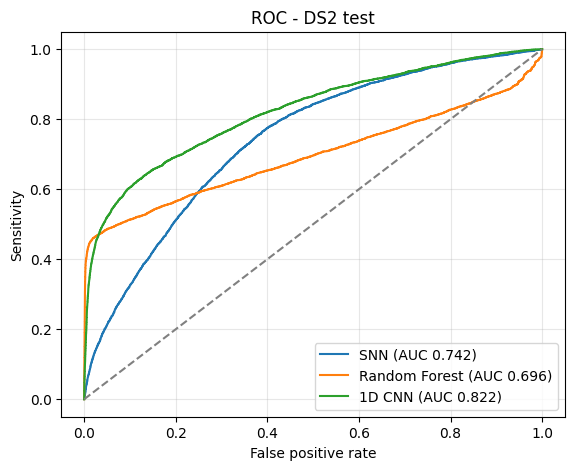

In [18]:
plt.figure(figsize=(6.5, 5))
for name, p in roc.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", c="grey")
plt.xlabel("False positive rate"); plt.ylabel("Sensitivity"); plt.title("ROC - DS2 test")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 11. Live-inference check

This replays a test record through the steps the dashboard will follow:
1. the 100 Hz stream arrives sample by sample;
2. a beat is reported about 80 ms after R (the firmware's `POST_R_WAIT`);
3. the backend takes the **max of the last 30 samples** as R;
4. it waits until 0.4 s after R, cuts the window, encodes it and runs the SNN.

If this agrees with the test-set predictions above, the exported model will
behave the same inside the dashboard.

In [19]:
def classify_live(stream_so_far, beat_reported_at, model=snn_model, thr=DECISION_THRESHOLD):
    recent = stream_so_far[max(0, beat_reported_at - 30): beat_reported_at]
    r_idx = beat_reported_at - len(recent) + int(np.argmax(recent))
    beat = beat_from_stream(stream_so_far, r_idx)
    if beat is None:
        return None
    spikes = torch.tensor(level_crossing_encode(beat)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, _, _ = model(spikes)
    p = float(torch.softmax(logits, 1)[0, 1])
    return int(p >= thr), p


@torch.no_grad()
def classify_window(beat, model=snn_model, thr=DECISION_THRESHOLD):
    logits, _, _ = model(torch.tensor(level_crossing_encode(beat)).unsqueeze(0).to(DEVICE))
    return int(float(torch.softmax(logits, 1)[0, 1]) >= thr)


for rec_id in TEST_RECORDS[:3]:
    path = record_path(rec_id)
    r, a = wfdb.rdrecord(path), wfdb.rdann(path, "atr")
    lead = r.sig_name.index("MLII") if "MLII" in r.sig_name else 0
    stream = device_stream(r.p_signal[:, lead], r.fs)
    truth, live, offline, same_r = [], [], [], 0
    for samp, sym in zip(a.sample, a.symbol):
        if sym not in N_SYMBOLS | ABN_SYMBOLS:
            continue
        idx0 = int(round(samp * FS_STREAM / r.fs))
        if idx0 < WARMUP_SEC * FS_STREAM:
            continue
        r_off = snap_to_peak(stream, idx0)               # how the training beats were cut
        beat = beat_from_stream(stream, r_off)
        if beat is None:
            continue
        reported = r_off + 9                             # beat reported ~80-90 ms after R
        out = classify_live(stream[: r_off + POST], reported)  # data only up to R + 0.4 s
        if out is None:
            continue
        recent = stream[reported - 30: reported]
        same_r += int(reported - 30 + int(np.argmax(recent)) == r_off)
        truth.append(int(sym in ABN_SYMBOLS)); live.append(out[0]); offline.append(classify_window(beat))
    truth, live, offline = map(np.array, (truth, live, offline))
    print(f"record {rec_id}: {len(live)} beats | live R == training R for {same_r / len(live):.1%} | "
          f"live vs offline verdict agree {np.mean(live == offline):.1%} | "
          f"live sensitivity {live[truth == 1].mean() if truth.sum() else float('nan'):.2f}, "
          f"false-alarm rate {live[truth == 0].mean():.3f}")

record 100: 2267 beats | live R == training R for 100.0% | live vs offline verdict agree 100.0% | live sensitivity 0.00, false-alarm rate 0.002
record 103: 2080 beats | live R == training R for 100.0% | live vs offline verdict agree 100.0% | live sensitivity 0.00, false-alarm rate 0.004
record 105: 2562 beats | live R == training R for 98.9% | live vs offline verdict agree 99.8% | live sensitivity 0.15, false-alarm rate 0.098


## 12. Save for the dashboard

`neurocardio_snn.pt` holds the weights and **every pre-processing parameter**,
so the backend can reproduce this notebook exactly. On **Colab** the browser
downloads it. On **Kaggle**, take it from the **Output** panel
(`/kaggle/working`). Put it in `NeuroCardio/host/models/`.

In [20]:
export = {
    "format": "neurocardio-snn-v1",
    "state_dict": {k: v.cpu() for k, v in snn_model.state_dict().items()},
    "config": {
        "architecture": {"class": "ECG_SNN", "n_in": 2, "hidden": HIDDEN, "beta": BETA,
                         "layers": "Linear(2,H)-Leaky-Linear(H,H)-Leaky-Linear(H,2)",
                         "surrogate": "fast_sigmoid(slope=25)", "readout": "sum of output over time, softmax"},
        "input": {"fs": FS_STREAM, "source": "firmware 'D,' stream (mV = q4 * Q4_TO_MV)",
                  "pre_samples": PRE, "post_samples": POST, "n_steps": N_STEPS,
                  "r_alignment": "argmax of the last 30 samples when the beat is reported",
                  "normalize": "(x - median) / std",
                  "encoding": "level-crossing, tracking reference, 2 channels [ON, OFF]",
                  "lc_threshold": LC_THRESHOLD},
        "classes": CLASSES,
        "decision_threshold": DECISION_THRESHOLD,
        "labels": "AAMI N (N,L,R,e,j) vs non-N (A,a,J,S,V,E,F); paced records excluded",
        "split": {"train": TRAIN_RECORDS, "val": VAL_RECORDS, "test": TEST_RECORDS,
                  "protocol": "de Chazal DS1/DS2 inter-patient"},
        "test_metrics": {k: float(v) for k, v in snn_metrics.items()},
        "quick_test": QUICK_TEST,
        "trained": time.strftime("%Y-%m-%d %H:%M"),
    },
}
torch.save(export, "neurocardio_snn.pt")
comparison.to_csv("neurocardio_model_comparison.csv")
eff.to_csv("neurocardio_snn_efficiency.csv")

# reload exactly as the dashboard will (CPU), and check it reproduces the results
ck = torch.load("neurocardio_snn.pt", map_location="cpu")
m2 = ECG_SNN(n_in=2, hidden=ck["config"]["architecture"]["hidden"], beta=ck["config"]["architecture"]["beta"])
m2.load_state_dict(ck["state_dict"]); m2.eval()
with torch.no_grad():
    lg, _, _ = m2(torch.tensor(S_test[:500]))
same = np.allclose(torch.softmax(lg, 1)[:, 1].numpy(), snn_prob[:500], atol=1e-4)
print("saved neurocardio_snn.pt -", "reload check OK" if same else "RELOAD MISMATCH")
print(json.dumps(ck["config"]["test_metrics"], indent=2))

outputs = ["neurocardio_snn.pt", "neurocardio_model_comparison.csv", "neurocardio_snn_efficiency.csv"]
where = {"Colab": "the Files panel (/content) - the browser also downloads them now",
         "Kaggle": "the Output panel on the right, or the version's Output tab"}.get(PLATFORM, WORK_DIR)
print(f"\nSaved to {WORK_DIR} -> {where}:")
for f in outputs:
    print(f"  {f}  ({os.path.getsize(f) / 1024:.0f} KB)")
    if not IN_COLAB:
        display(FileLink(f))
if IN_COLAB:
    for f in outputs:
        colab_files.download(f)

saved neurocardio_snn.pt - reload check OK
{
  "Accuracy": 0.7495263051804072,
  "Precision": 0.23089956869993838,
  "Sensitivity": 0.5513056270687753,
  "Specificity": 0.773929185909626,
  "F1": 0.3254804038649441,
  "ROC-AUC": 0.742321441839728
}

Saved to /content -> the Files panel (/content) - the browser also downloads them now:
  neurocardio_snn.pt  (24 KB)
  neurocardio_model_comparison.csv  (0 KB)
  neurocardio_snn_efficiency.csv  (0 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. What to say in the review

* **Protocol:** MIT-BIH, AAMI N vs non-N, paced records excluded, **inter-patient
  DS1/DS2 split**. Test patients were never seen in training.
* **Device-matched:** training beats pass through a software copy of the
  NeuroCardio firmware (ADC, moving-average notch, high-pass, 100 Hz stream), so
  the model is trained on the same signal the electrodes deliver.
* **Efficiency:** report input sparsity and synaptic operations per beat from
  section 9, and call the energy figures *estimates for event-driven hardware*.
* **Known gaps:** MIT-BIH is lead MLII, while the NeuroCardio belt is a different lead. The
  live accuracy on your own electrodes is **not yet validated**. Recording and
  labelling a few minutes of your own data is the next step.